<a href="https://colab.research.google.com/github/qprojects0/NBA-Matrices-and-Machines-Project/blob/main/NBA_Matrices_and_Machines_Project_Quinlan_Guillermo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Setup

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

from sklearn import linear_model

In [ ]:
file_id = "1xZJTMPwOGEqsHK7z4MLOymCVd7QF4qgB"
url = f"https://drive.google.com/file/d/1xZJTMPwOGEqsHK7z4MLOymCVd7QF4qgB/view?usp=sharing"
df = pd.read_csv("https://drive.usercontent.google.com/download?id=1xZJTMPwOGEqsHK7z4MLOymCVd7QF4qgB&export=download&confirm=t")

In [ ]:
df.head()

,age,g,gs,mp_per_game,fga_per_game,fg_percent,x3pa_per_game,x3p_percent,fta_per_game,ft_percent,ast_per_game,pts_per_game
0,26.0,73,57.0,23.9,8.2,0.528,1.3,0.278,1.9,0.554,1.4,10.1
1,32.0,32,11.0,22.8,4.3,0.504,0.0,NaN,2.5,0.580,1.5,5.8
2,28.0,73,73.0,32.4,15.7,0.442,5.5,0.318,5.8,0.778,3.2,20.1
3,25.0,62,13.0,15.7,4.5,0.436,2.1,0.266,0.7,0.837,0.8,5.1
4,25.0,42,13.0,15.5,4.0,0.424,1.5,0.185,0.7,0.862,0.7,4.3


# Numerical Data Summary

In [ ]:
df.dropna().head()

,age,g,gs,mp_per_game,fga_per_game,fg_percent,x3pa_per_game,x3p_percent,fta_per_game,ft_percent,ast_per_game,pts_per_game
0,26.0,73,57.0,23.9,8.2,0.528,1.3,0.278,1.9,0.554,1.4,10.1
2,28.0,73,73.0,32.4,15.7,0.442,5.5,0.318,5.8,0.778,3.2,20.1
3,25.0,62,13.0,15.7,4.5,0.436,2.1,0.266,0.7,0.837,0.8,5.1
4,25.0,42,13.0,15.5,4.0,0.424,1.5,0.185,0.7,0.862,0.7,4.3
5,25.0,20,0.0,16.2,5.5,0.455,3.2,0.349,0.7,0.786,0.9,6.7


The average player in the NBA averages 8.4 ppg

In [ ]:
df['pts_per_game'].mean()

np.float64(8.353039983202855)

This statistic shows that NBA players’ minutes per game typically vary by roughly 10 minutes away from the average.

In [ ]:
np.std(df['mp_per_game'])

10.203220556559497

The highest average of field goals attempted per game in a single season (shots attempted) is 39.5 attempts, belonging to Wilt Chamberlain. This shows that Wilt was an extreme outlier (ball hogger) because he attempted far more shots per game than the average NBA player.

In [ ]:
df['fga_per_game'].describe()

,fga_per_game
count,33339.000000
mean,7.142935
std,4.821711
min,0.000000
25%,3.400000
50%,6.000000
75%,10.000000
max,39.500000


# Visual Data Summary

In [ ]:
df.head()

,age,g,gs,mp_per_game,fga_per_game,fg_percent,x3pa_per_game,x3p_percent,fta_per_game,ft_percent,ast_per_game,pts_per_game
0,26.0,73,57.0,23.9,8.2,0.528,1.3,0.278,1.9,0.554,1.4,10.1
1,32.0,32,11.0,22.8,4.3,0.504,0.0,NaN,2.5,0.580,1.5,5.8
2,28.0,73,73.0,32.4,15.7,0.442,5.5,0.318,5.8,0.778,3.2,20.1
3,25.0,62,13.0,15.7,4.5,0.436,2.1,0.266,0.7,0.837,0.8,5.1
4,25.0,42,13.0,15.5,4.0,0.424,1.5,0.185,0.7,0.862,0.7,4.3


In [ ]:
df = df.dropna()

The histogram of points per game is right-skewed. Most player-seasons have lower scoring averages, with the largest group scoring roughly between 4 and 8 points per game. As points per game increase, the number of player-seasons decreases, displaying rare elite high-scoring player-seasons.

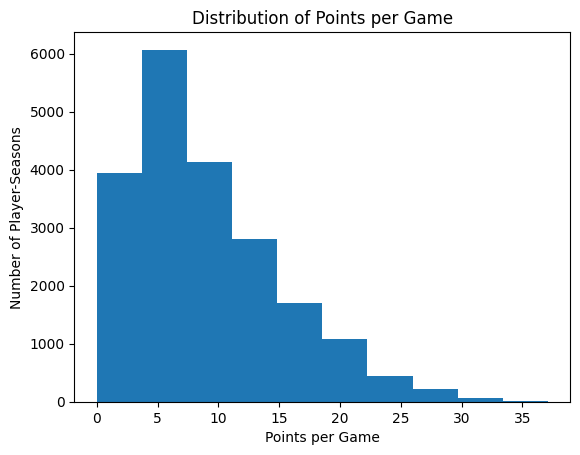

In [ ]:
fig, ax = plt.subplots()
ax.hist(df['pts_per_game'])
ax.set(xlabel="Points per Game", ylabel="Number of Player-Seasons", title="Distribution of Points per Game")

fig.show()

Most player-seasons fall between approximately 10 and 35 minutes per game, with the highest density around 15 to 20 minutes per game. Overall, the distribution is evenly spread throughout because NBA players have different roles such as bench players and starters who play many minutes.

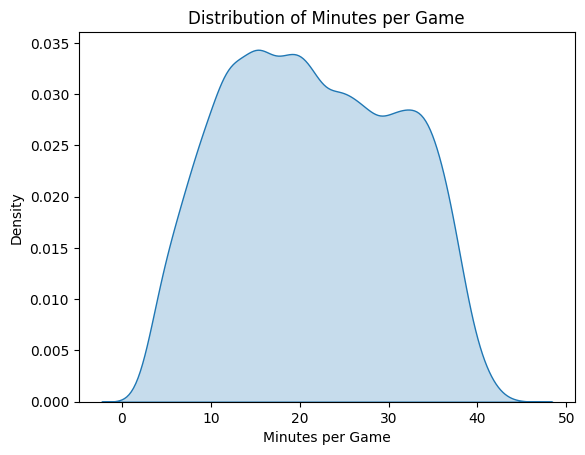

In [ ]:
fig, ax = plt.subplots()
sns.kdeplot(data = df['mp_per_game'], fill='true')
plt.xlabel("Minutes per Game")
plt.ylabel("Density")
plt.title("Distribution of Minutes per Game")

fig.show()

# Visual Bivariate Analysis

As players attempt more field goals, they generally score more points. The points form a clear upward pattern, meaning shot attempts are strongly associated with scoring. However, players with the same number of attempts can score different amounts because of factors such as shooting percentage, three-point shots, and free throws. Therefore, this graph is not direct proof that attempting more shots will guarantee more points.

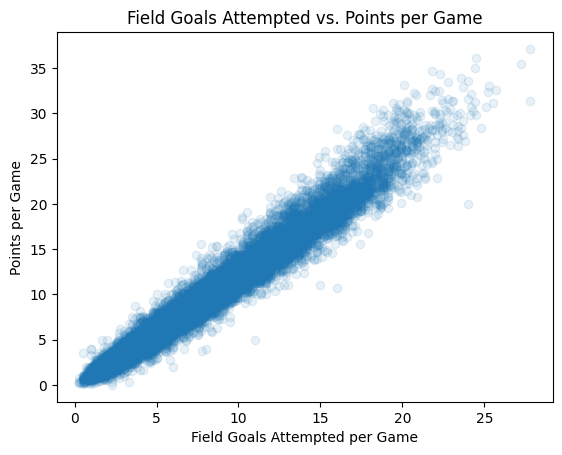

In [ ]:
fig, ax = plt.subplots()
ax.scatter(df['fga_per_game'], df['pts_per_game'], alpha=0.1)
ax.set(xlabel="Field Goals Attempted per Game", ylabel="Points per Game", title="Field Goals Attempted vs. Points per Game")

fig.show()

This scatterplot is a lot more broad in a sense that there isn't a clear cut upward trend, yet there is still some observations to be made. For example, having more assists can potentially hinder a player's points due to passing the ball more often. We see this visually with players in the 12-14 assists range having fewer points in compairason to a player simply averaging around 4 assists.

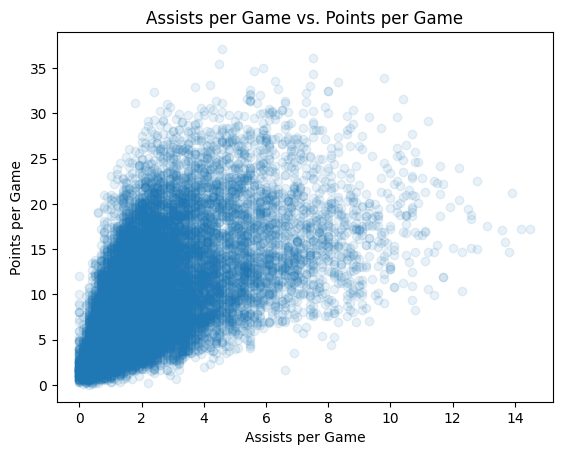

In [ ]:
fig, ax = plt.subplots()
ax.scatter(df['ast_per_game'], df['pts_per_game'], alpha=0.1)
ax.set(xlabel="Assists per Game", ylabel="Points per Game", title="Assists per Game vs. Points per Game")

fig.show()

# PPG Linear Model 🏀

In [ ]:
df.head()

,age,g,gs,mp_per_game,fga_per_game,fg_percent,x3pa_per_game,x3p_percent,fta_per_game,ft_percent,ast_per_game,pts_per_game
0,26.0,73,57.0,23.9,8.2,0.528,1.3,0.278,1.9,0.554,1.4,10.1
2,28.0,73,73.0,32.4,15.7,0.442,5.5,0.318,5.8,0.778,3.2,20.1
3,25.0,62,13.0,15.7,4.5,0.436,2.1,0.266,0.7,0.837,0.8,5.1
4,25.0,42,13.0,15.5,4.0,0.424,1.5,0.185,0.7,0.862,0.7,4.3
5,25.0,20,0.0,16.2,5.5,0.455,3.2,0.349,0.7,0.786,0.9,6.7


In [ ]:
true_ppg = df['pts_per_game']

In [ ]:
inputs = df.drop(columns = ['pts_per_game']).drop_duplicates()

In [ ]:
ppg_linear_model = linear_model.LinearRegression()

In [ ]:
ppg_linear_model.fit(X = inputs, y = true_ppg)

LinearRegression()

In [ ]:
predicted_ppg = ppg_linear_model.predict(inputs)

In [ ]:
mean_squared_error(true_ppg, predicted_ppg)

0.3110727204769324

In [ ]:
ppg_linear_model.coef_

array([ 1.03359590e-02, -1.01678461e-03,  8.14678705e-03, -3.43681800e-02,
        9.40101112e-01,  8.91320239e+00,  2.91738651e-01,  3.42494418e-01,
        8.54866155e-01,  1.16942070e+00, -1.75198414e-02])

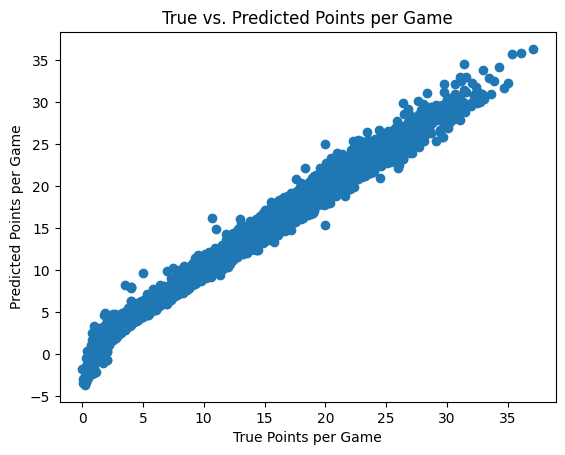

In [ ]:
fig, ax = plt.subplots()
ax.scatter(true_ppg, predicted_ppg)
ax.set(xlabel="True Points per Game", ylabel="Predicted Points per Game", title="True vs. Predicted Points per Game")

fig.show()

I tried experimenting with dropping columns, outcome didn't change

In [ ]:
inputs = df.drop(columns = ['pts_per_game', 'gs', 'g', 'age']).drop_duplicates()

In [ ]:
ppg_linear_model.fit(X = inputs, y = true_ppg)

LinearRegression()

In [ ]:
ppg_linear_model.predict(X = inputs)

array([ 9.87613056, 20.79037156,  5.22838254, ...,  7.4237126 ,
        6.63042418,  1.49234072])

In [ ]:
mean_squared_error(true_ppg, predicted_ppg)

0.3110727204769324

# Field-Goal Percentage Correlation to Points per Game Data ⚡

RQ: Is a higher field-goal percentage associated with more points per game?

Hypothesis: **Players with higher field-goal percentages will tend to have higher points per game.**

In [ ]:
df.head()

,age,g,gs,mp_per_game,fga_per_game,fg_percent,x3pa_per_game,x3p_percent,fta_per_game,ft_percent,ast_per_game,pts_per_game
0,26.0,73,57.0,23.9,8.2,0.528,1.3,0.278,1.9,0.554,1.4,10.1
2,28.0,73,73.0,32.4,15.7,0.442,5.5,0.318,5.8,0.778,3.2,20.1
3,25.0,62,13.0,15.7,4.5,0.436,2.1,0.266,0.7,0.837,0.8,5.1
4,25.0,42,13.0,15.5,4.0,0.424,1.5,0.185,0.7,0.862,0.7,4.3
5,25.0,20,0.0,16.2,5.5,0.455,3.2,0.349,0.7,0.786,0.9,6.7


In [ ]:
df['fga_per_game'].mean()

np.float64(7.5327560904021125)

I removed rows with missing field-goal percentage and points-per-game values because they cannot be used to compare shooting efficiency with scoring. I also kept players who played at least 41 games and attempted at least one field goal per game, reducing the influence of records based on very limited playing time or shooting data.

In [ ]:
nba = df.dropna(subset = ['fg_percent', 'pts_per_game'])
nba = nba[nba['g'] >= 41]
nba = nba[nba['fga_per_game'] >= 1]

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
plt.style.available

['Solarize_Light2',
 '_classic_test_patch',
 '_mpl-gallery',
 '_mpl-gallery-nogrid',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

In [ ]:
plt.style.use('seaborn-v0_8')

In [ ]:
plt.rcParams.update({
    'axes.titlesize': 25,
    'axes.labelsize': 24,
    'figure.titlesize': 18,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10
})

The graph shows a slight upward overall relationship: players with higher field-goal percentages tend to score more points per game. However, the spread is large, so field-goal percentage alone is not enough to predict scoring.

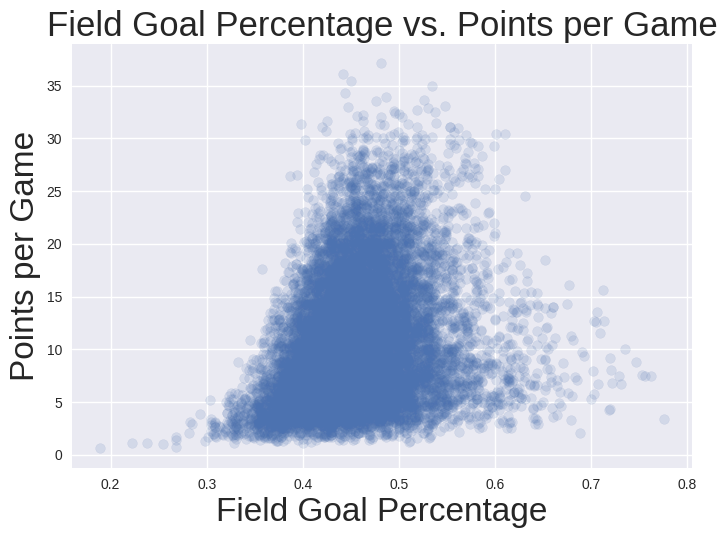

In [ ]:
fig, ax = plt.subplots()
ax.scatter(nba['fg_percent'], nba['pts_per_game'], alpha=0.15)
ax.set(xlabel="Field Goal Percentage", ylabel="Points per Game", title="Field Goal Percentage vs. Points per Game")

fig.show()

In [ ]:
nba['fg_group'] = pd.qcut(nba['fg_percent'], q=3, labels=['Low FG%', 'Medium FG%', 'High FG%'])

In [ ]:
print(pd.qcut(nba['fg_percent'], q=3).unique())

[(0.474, 0.776], (0.432, 0.474], (0.188, 0.432]]
Categories (3, interval[float64, right]): [(0.188, 0.432] < (0.432, 0.474] < (0.474, 0.776]]


Players with higher field-goal percentages had higher average points per game. The low-FG% group averaged about 8 PPG, while the high-FG% group averaged about 12 PPG. This supports the hypothesis that more efficient shooters tend to score more. However, the difference between the medium- and high-FG% groups is smaller, suggesting that field-goal percentage is only one factor related to scoring.

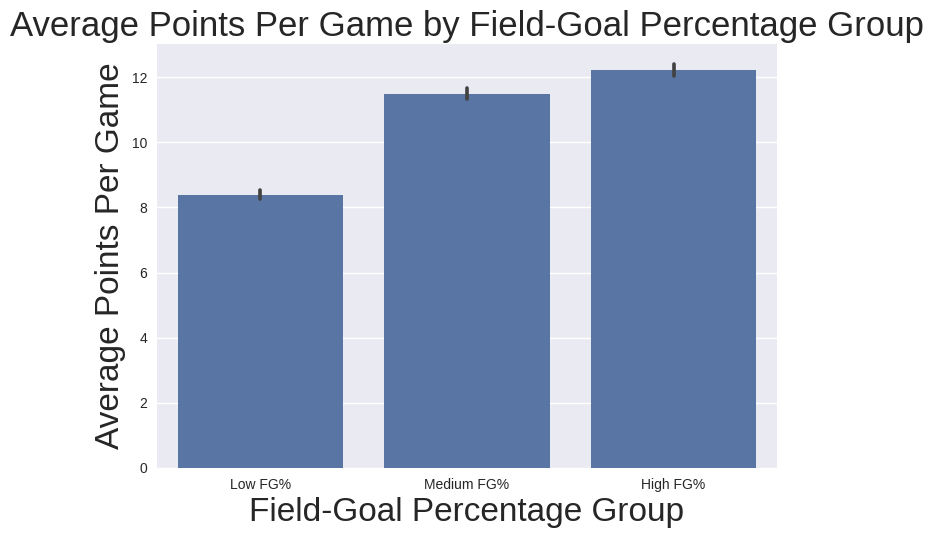

In [ ]:
plt.figure()

sns.barplot(data = nba, x = 'fg_group', y = 'pts_per_game',)
plt.xlabel("Field-Goal Percentage Group")
plt.ylabel("Average Points Per Game")
plt.title("Average Points Per Game by Field-Goal Percentage Group")

fig.show()

The graph shows that players who attempt more field goals per game generally score more points per game. This suggests shot volume is a major factor in scoring, helping explain why field-goal percentage alone has only a modest relationship with points per game.

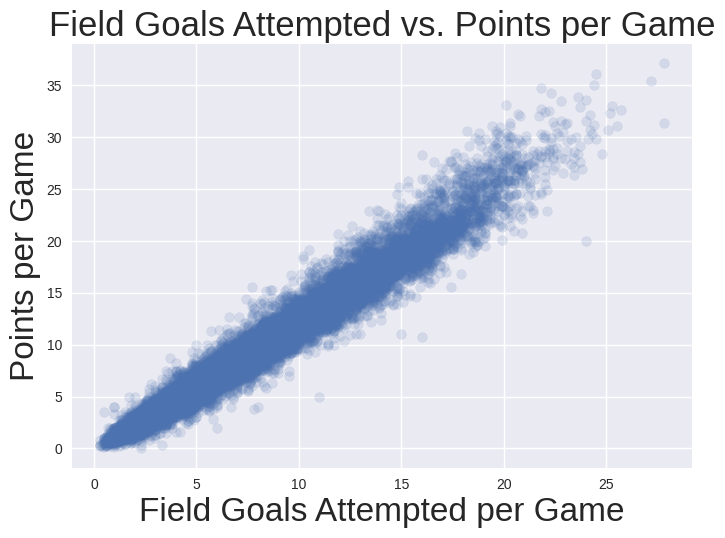

In [ ]:
fig, ax = plt.subplots()
ax.scatter(df['fga_per_game'], df['pts_per_game'], alpha=0.15)
ax.set(xlabel="Field Goals Attempted per Game", ylabel="Points per Game", title="Field Goals Attempted vs. Points per Game")

fig.show()

The hypothesis is technically right, as the players with higher field-goal percentages tend to score more points per game. The FG% group bar chart provides the clearest evidence, with the high-FG% group averaging about 12 PPG compared with about 8 PPG for the low-FG% group. However, the scatterplot shows that this relationship is not perfect. The field-goals-attempted graph suggests that shot volume is also a major factor in scoring. Therefore, NBA scoring appears to depend on both how efficiently a player shoots and how often they shoot.

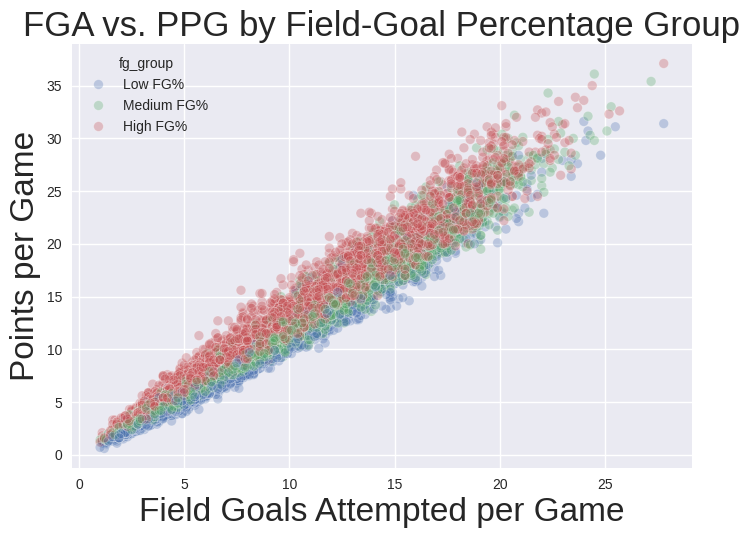

In [ ]:
sns.scatterplot(data = nba, x = 'fga_per_game', y = 'pts_per_game', hue = 'fg_group', alpha = 0.3)
plt.xlabel("Field Goals Attempted per Game")
plt.ylabel("Points per Game")
plt.title("FGA vs. PPG by Field-Goal Percentage Group")
plt.show()

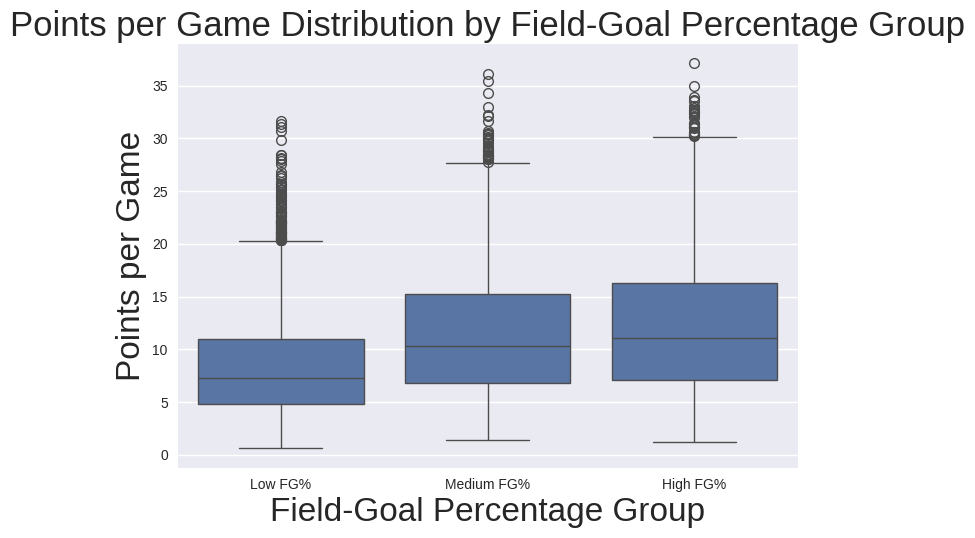

In [ ]:
sns.boxplot(data=nba, x='fg_group', y='pts_per_game')
plt.xlabel("Field-Goal Percentage Group")
plt.ylabel("Points per Game")
plt.title("Points per Game Distribution by Field-Goal Percentage Group")
plt.show()